In [1]:
import matplotlib.pyplot as plt
import numpy as np  
import pandas as pd
import scipy
import os,sys,matplotlib
import seaborn as sns
from statannotations.Annotator import Annotator

sys.path.append(os.path.abspath(".."))
from func_plot import plt_setting,plot_scatter,plot_conn_matrix,plot_conn_comparison_scatter,style_axis

In [2]:
if_save_fig = False
plt_setting(plt)

In [3]:
# ctx_labels is stored as an object array.
with np.load("../prepare_SC_EC_FC.npz", allow_pickle=True) as data:
    ctx_labels = data["ctx_labels"]
    sc_ctx = data["sc_ctx"]
    fc_ctx = data["fc_ctx"]
    ftract_ctx = data["ftract_ctx"]

# num of nodes
N = len(ctx_labels)

In [4]:
S=np.copy(sc_ctx) # SC
S=S/S.max() # SC除以最大值标准化

E=np.copy(ftract_ctx)
E[np.diag_indices_from(E)]=np.nan # EC 对角元素去掉

F=np.copy(np.tanh(fc_ctx)) # 将fisher z-score 之后的FC转换回R值
F[np.diag_indices_from(F)]=np.nan # FC 对角元素去掉
print(np.nanmax(F))

0.891101127383349


In [5]:
# Create a matrix with ones,Set the lower triangle to NaN
mask_tril = np.ones((N, N))
mask_tril[np.tril_indices(N, 0)] = np.nan

mask_diag = np.ones((N, N))
mask_diag[np.diag_indices_from(mask_diag)] = np.nan

In [6]:
def boxplot(ax,df,if_annotator=True):
    x=df.keys()[0]
    y=df.keys()[1]
    sns.boxplot(ax=ax,data=df,x=x,y=y,width=0.5,linewidth=0.5,flierprops={"marker": 'o','markersize':.5,'alpha':.5})

    if if_annotator:
        pairs=[('SC=0', 'SC>0')]
        annotator = Annotator(ax, pairs, data=df,x=x,y=y,)
        annotator.configure(test='t-test_ind', text_format='full', show_test_name=False)
        annotator.apply_and_annotate()

def scatter1(ax,x,y,text_xy1=(0,0),text_xy2=(0,0),markersize=.5,alphadot=.3):
    cmap=plt.colormaps['tab10']
    mask=(~np.isnan(x))&(~np.isnan(y))
    x=np.copy(x[mask])
    y=np.copy(y[mask])

    sns.regplot(ax=ax,x=x,y=y,scatter=False,line_kws={"color": cmap(7),'alpha':0.5})
    ax.text(text_xy1[0],text_xy1[1],"r = {:.3f}\np = {:.1e}".format(scipy.stats.pearsonr(x, y).statistic,scipy.stats.pearsonr(x, y).pvalue))

    sns.regplot(ax=ax,x=x[x==0],y=y[x==0],label='SC=0',scatter_kws={'s':markersize,'color':cmap(0),'alpha':alphadot},fit_reg=False)

    sns.regplot(ax=ax,x=x[x!=0],y=y[x!=0],label='SC>0',scatter_kws={'s':markersize,'color':cmap(1),'alpha':alphadot},line_kws={"color": cmap(1),'alpha':0.5})
    ax.text(text_xy2[0],text_xy2[1],
            "r = {:.3f}\np = {:.1e}".format(scipy.stats.pearsonr(x[x!=0], y[x!=0]).statistic,scipy.stats.pearsonr(x[x!=0], y[x!=0]).pvalue),
            color=cmap(1))
    
    ax.legend()
    

SC=0 vs. SC>0: t-test independent samples, P_val:1.929e-118 t=-2.442e+01
SC=0 vs. SC>0: t-test independent samples, P_val:6.483e-99 t=-2.164e+01


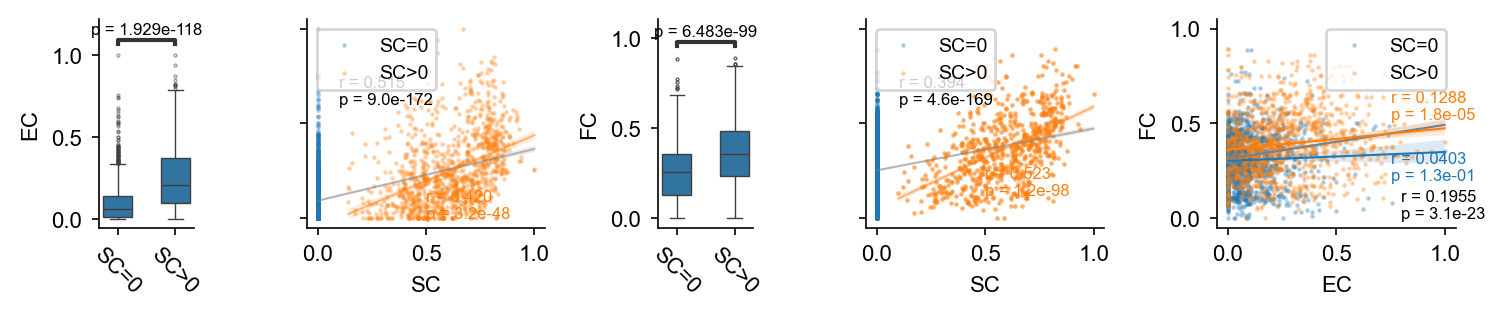

In [7]:
_,axs=plt.subplots(1,5,figsize=(190/25.4, 40/25.4),width_ratios=([2,5,2,5,5]))

for ax in axs.flat : style_axis(ax); ax.set_ylim([-.05,1.05])

markersize=.5
alphadot=.3

ax=axs[0]

x=E[S==0]
y=E[S!=0]
df = pd.DataFrame({'SC': ['SC=0']*x.size + ['SC>0']*y.size,'EC': np.concatenate([x, y])})
boxplot(ax,df)
ax.tick_params(axis="x", labelrotation=-45)
ax.set_xlabel(None)

ax=axs[2]
x=F[S==0]
y=F[S!=0]
df = pd.DataFrame({'SC': ['SC=0']*x.size + ['SC>0']*y.size,'FC': np.concatenate([x, y])})
boxplot(ax,df)
ax.tick_params(axis="x", labelrotation=-45)
ax.set_xlabel(None)

ax=axs[1]
scatter1(ax,S,E,(.1,.6),(.5,.0))
ax.set_xlabel('SC')
# ax.set_ylabel('EC')
ax.set_yticklabels([])

ax=axs[3]
scatter1(ax,S,F,(.1,.6),(.5,.12))
ax.set_xlabel('SC')
# ax.set_ylabel('FC')
ax.set_yticklabels([])

ax=axs[4]
plot_conn_comparison_scatter(ax,E,F,S,text_xy1=(0.8,0.0),text_xy2=(0.75,0.2),text_xy3=(0.75,0.52),markersize=markersize,alphadot=alphadot)
ax.set_xlabel('EC')
ax.set_ylabel('FC')

plt.tight_layout()

if if_save_fig: plt.savefig('./Analysis_edge/fig4_scatter_boxplot_ECFCSC.svg')

In [8]:
def edge_corr(X,Y):
    mask=(~np.isnan(X))&(~np.isnan(Y))
    x=X[mask]
    y=Y[mask]
    return scipy.stats.pearsonr(x, y).statistic, scipy.stats.pearsonr(x, y).pvalue

def node_wise_edge_corr(X,Y,axis='row'):

    rs=[]
    for i in range(N):

        if axis=='row':
            x=X[i,:]
            y=Y[i,:]
        elif axis=='col':
            x=X[:,i]
            y=Y[:,i]

        mask=(~np.isnan(x))&(~np.isnan(y))

        try:
            r = scipy.stats.pearsonr(x[mask], y[mask]).statistic
            rs.append(r)
        except:
            pass

    return np.asarray(rs)

rs_SvsF=node_wise_edge_corr(S,F)
rs_FvsEinp=node_wise_edge_corr(F,E,axis='row')
rs_FvsEout=node_wise_edge_corr(F,E,axis='col')
rs_SvsEinp=node_wise_edge_corr(S,E,axis='row')
rs_SvsEout=node_wise_edge_corr(S,E,axis='col')

## plot
def myplot_hist1(ax,rs,rs_label,r,r_label,bins,linewidth=1,):
    cmap=plt.colormaps['tab10']
    ax.hist(rs,bins=bins,label=rs_label,alpha=0.5,color=cmap(0))
    ax.plot(rs.mean()*np.ones(2),ax.get_ylim(),"-",label='mean',color=cmap(0),linewidth=linewidth)
    ax.plot(r*np.ones(2),ax.get_ylim(),label=r_label,color=cmap(3),linewidth=linewidth)
    ax.set_xlabel('r-value')
    ax.legend()
    print(np.sum(rs<r)/rs.size)


0.08064516129032258
0.22580645161290322


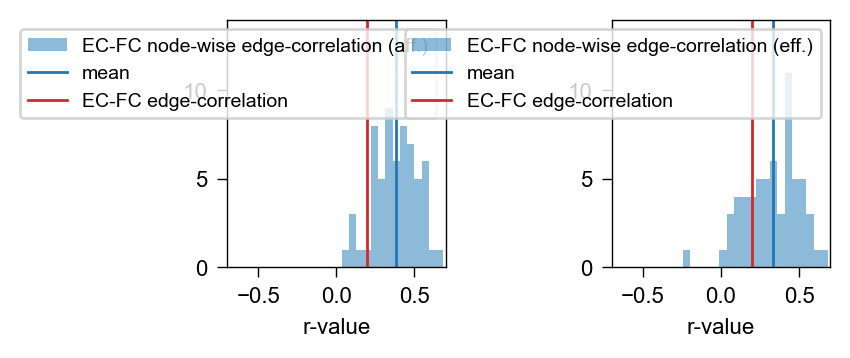

In [9]:
fig,axs=plt.subplots(1,2,figsize=(100/25.4, 45/25.4))

for ax in axs:
    ax.set_ylim([0,14])
    ax.set_xlim([-0.7,0.7])

bins=np.histogram(np.hstack((rs_FvsEinp,rs_FvsEout)), bins=20)[1]
myplot_hist1(axs[0],rs_FvsEinp,"EC-FC node-wise edge-correlation (aff.)",edge_corr(F,E)[0],'EC-FC edge-correlation',bins)

myplot_hist1(axs[1],rs_FvsEout,"EC-FC node-wise edge-correlation (eff.)",edge_corr(F,E)[0],'EC-FC edge-correlation',bins)

plt.tight_layout()


/tmp/ipykernel_3210823/3437166242.py:7: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = matplotlib.cm.get_cmap('tab10', N)


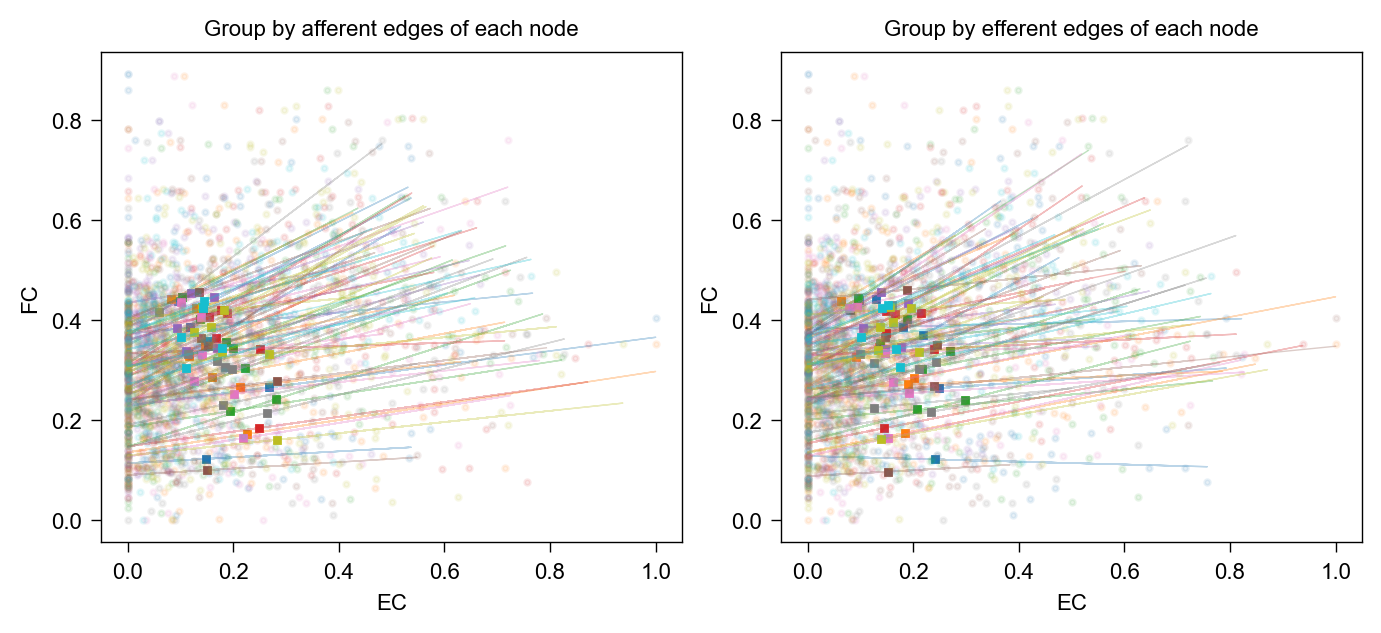

In [10]:
_,axs=plt.subplots(1,2,figsize=(175/25.4, 80/25.4))

for ax,group in zip(axs,['row','col']):

    ax.set_xlabel('EC')
    ax.set_ylabel('FC')
    cmap = matplotlib.cm.get_cmap('tab10', N)

    for i in range(N):

        if group == 'row':
            x=E[i,:]
            y=F[i,:]
        else:
            x=E[:,i]
            y=F[:,i]

        mask=(~np.isnan(x))&(~np.isnan(y))
        if mask.sum()>2:
            x=x[mask]
            y=y[mask]
            ax.plot(x,y,'.',color=cmap(i),alpha=0.1)

            m, b = np.polyfit(x, y, 1)
            ax.plot(x, m*x+b,color=cmap(i),alpha=0.3)

            ax.plot(np.mean(x),np.mean(y),'s',color=cmap(i), alpha=1., markersize=2)

    if group == 'row':
        ax.set_title('Group by afferent edges of each node') #(row)
    else:
        ax.set_title('Group by efferent edges of each node') #(col)
    

plt.tight_layout()


/tmp/ipykernel_3210823/266795810.py:9: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = matplotlib.cm.get_cmap('tab10', 10)


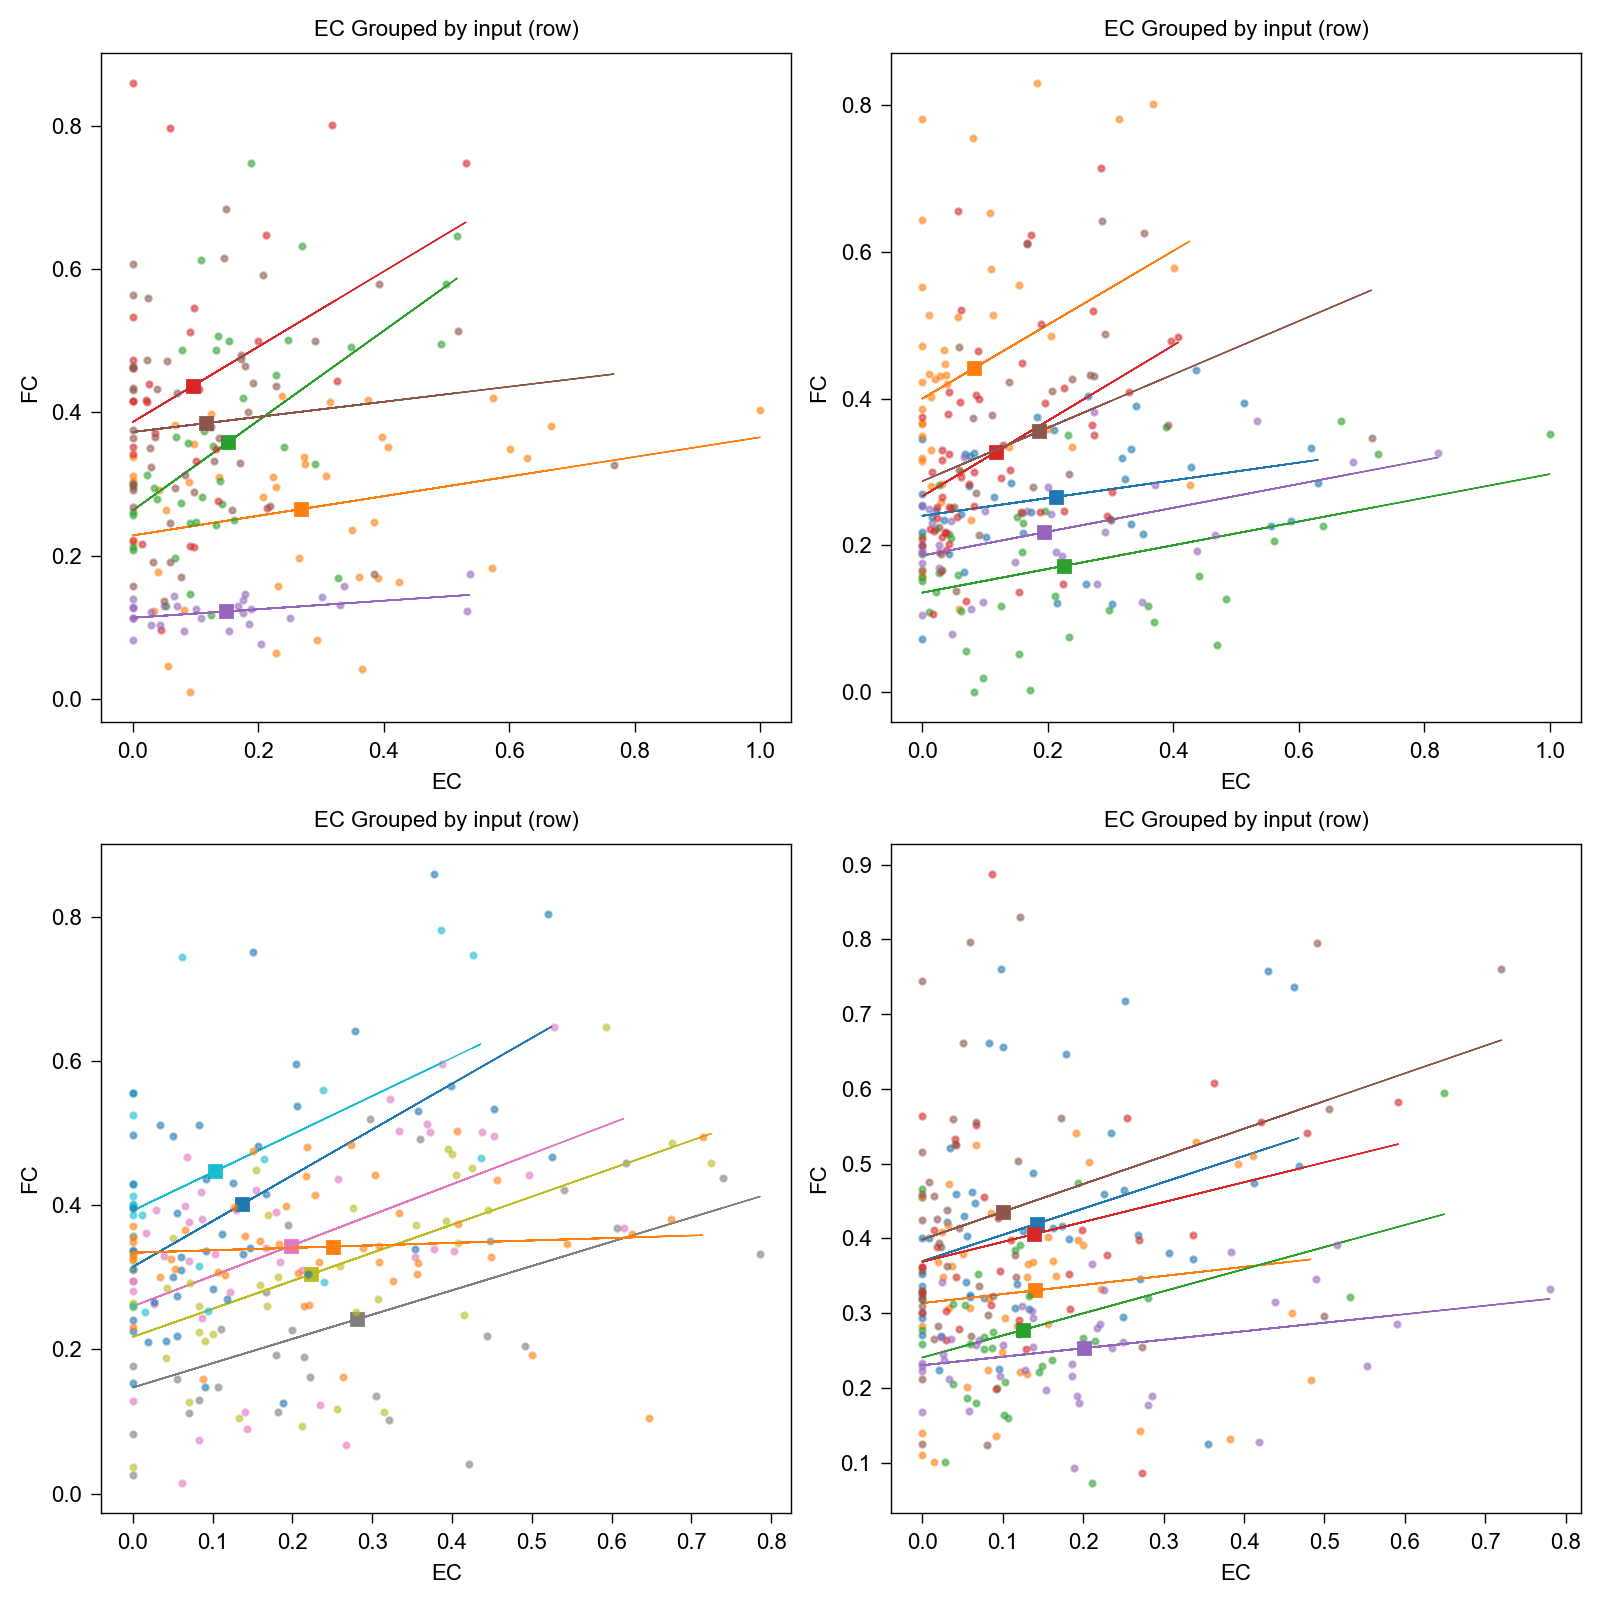

In [11]:
_,axs=plt.subplots(2,2,figsize=(8,8))

group='row'

for ax,i_list in [(axs[0,0],range(6)),(axs[0,1],range(10,16)),(axs[1,0],range(16,22)),(axs[1,1],range(40,46))]:
    ax.set_xlabel('EC')
    ax.set_ylabel('FC')
    for i in i_list:
        cmap = matplotlib.cm.get_cmap('tab10', 10)
        if group == 'row':
            x=E[i,:]
            y=F[i,:]
        else:
            x=E[:,i]
            y=F[:,i]
        c=cmap(i%10)

        mask=(~np.isnan(x))&(~np.isnan(y))
        if mask.sum()>2:
            x=x[mask]
            y=y[mask]
            ax.plot(x,y,'.',color=c,alpha=0.5)

            m, b = np.polyfit(x, y, 1)
            ax.plot(x, m*x+b,color=c,alpha=1)

            ax.plot(np.mean(x),np.mean(y),'s',color=c,alpha=1)

    if group == 'row':
        ax.set_title('EC Grouped by input (row)')
    else:
        ax.set_title('EC Grouped by output (col)')
plt.tight_layout()